<a href="https://colab.research.google.com/github/samiurrahman280/CVPR-ASSIGNMENT-1/blob/main/Vegetable_CNN_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q tensorflow scikit-learn seaborn

In [12]:
import os
import zipfile
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from google.colab import drive

drive.mount('/content/drive')

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
ZIP_PATH = (
    "/content/drive/MyDrive/CNN ASSIGNMENT/Vegetable Image Dataset for Classification Models A Bangladeshi Perspective.zip"
)

EXTRACT_PATH = "/content/vegetable_dataset"

# Extract only once
if not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [15]:
import zipfile

IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp'
}

def get_images(folder):
    return [
        p for p in Path(folder).iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

# If a nested ZIP exists, let's make sure it is fully extracted
nested_zip_path = "/content/vegetable_dataset/Vegetable Image Dataset for Classification Models A Bangladeshi Perspective/Vegetable_Image.zip"
final_extract_path = "/content/vegetable_dataset_final"

if os.path.exists(nested_zip_path) and not os.path.exists(final_extract_path):
    print("Extracting nested zip to:", final_extract_path)
    with zipfile.ZipFile(nested_zip_path, 'r') as zip_ref:
        zip_ref.extractall(final_extract_path)

# We will search both the original extract path and the nested extract path
search_paths = [EXTRACT_PATH, final_extract_path]
candidates = []

for s_path in search_paths:
    if not os.path.exists(s_path):
        continue
    for folder in Path(s_path).rglob("*"):
        if not folder.is_dir():
            continue

        class_folders = [
            sub for sub in folder.iterdir()
            if sub.is_dir() and len(get_images(sub)) > 0
        ]

        if len(class_folders) >= 2:
            candidates.append((folder, class_folders))

if not candidates:
    raise ValueError(
        "Could not find class folders. "
        "Inspect the extracted dataset structure."
    )

# Select the folder containing the most image classes
DATASET_PATH, class_folders = max(
    candidates,
    key=lambda x: len(x[1])
)

class_folders = sorted(class_folders)

print("Dataset location:", DATASET_PATH)
print("Number of classes:", len(class_folders))

for folder in class_folders:
    print(folder.name, ":", len(get_images(folder)), "images")

Dataset location: /content/vegetable_dataset_final/Vegetable_Image/Dataset
Number of classes: 12
Bean : 454 images
Bitter melon : 306 images
Brinjal : 373 images
Cucumber : 342 images
Garlic : 349 images
Green Chili : 497 images
Ladies finger : 308 images
Onion : 357 images
Pointed gourd : 329 images
Potato : 365 images
Radish : 310 images
Tomato : 329 images


In [16]:
image_paths = []
image_labels = []

for label, folder in enumerate(class_folders):

    for image in get_images(folder):
        image_paths.append(str(image))
        image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Available images:", len(image_paths))

if len(image_paths) < 2500:
    raise ValueError("Dataset contains fewer than 2,500 images.")

X, _, y, _ = train_test_split(
    image_paths,
    image_labels,
    train_size=2500,
    random_state=SEED,
    stratify=image_labels
)

print("Selected images:", len(X))

Available images: 4319
Selected images: 2500


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 1750
Validation: 375
Testing: 375


In [18]:
IMG_SIZE = 128
BATCH_SIZE = 32

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = image / 255.0

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(X_train, y_train, True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Preprocessing completed.")

Preprocessing completed.


In [20]:
# Extract class names from the folder list
class_names = [folder.name for folder in class_folders]
num_classes = len(class_names)

model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(128, 128, 3)
    ),

    # First convolutional layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128, activation='relu'
    ),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes, activation='softmax'
    )
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,868 (28.21 MB)

 Trainable params: 7,393,868 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.4989 - loss: 1.6205 - val_accuracy: 0.7067 - val_loss: 0.9208
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.7949 - loss: 0.6715 - val_accuracy: 0.8507 - val_loss: 0.4730
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.8869 - loss: 0.3733 - val_accuracy: 0.8800 - val_loss: 0.3394
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9297 - loss: 0.2339 - val_accuracy: 0.8933 - val_loss: 0.2994
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9554 - loss: 0.1397 - val_accuracy: 0.9040 - val_loss: 0.3109
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9709 - loss: 0.0867 - val_accuracy: 0.9360 - val_loss: 0.2405
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9800 - loss: 0.0705 - val_accuracy: 0.9307 - val_loss: 0.2145
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.9863 - loss: 0.0567 - val_accuracy: 0.9040 - val_l

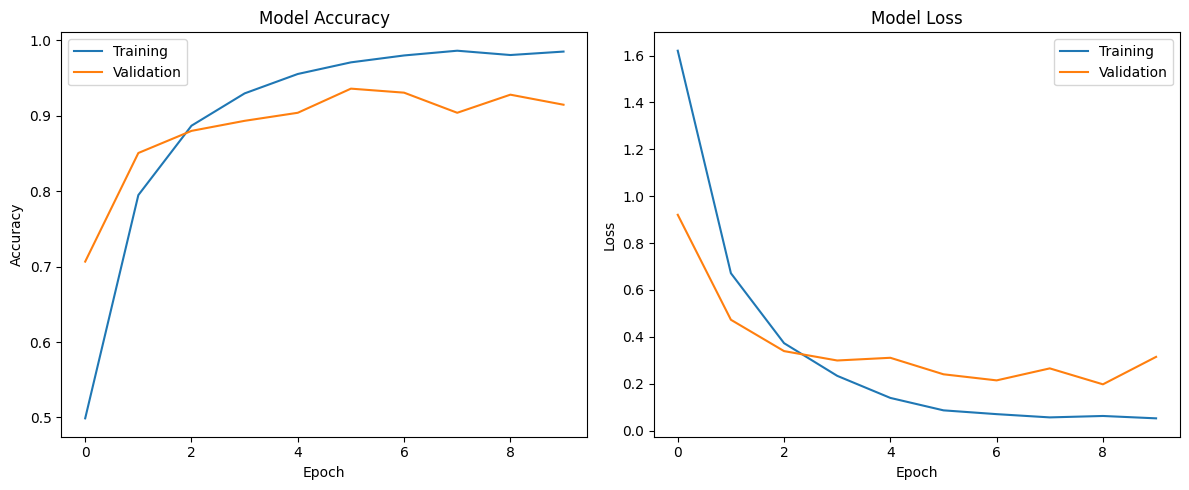

In [22]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9280 - loss: 0.2253
Test Loss: 0.2253
Test Accuracy: 92.8 %


In [24]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0
))

               precision    recall  f1-score   support

         Bean       0.94      0.82      0.88        39
 Bitter melon       0.88      0.85      0.86        26
      Brinjal       0.91      0.94      0.93        33
     Cucumber       0.90      0.90      0.90        30
       Garlic       0.97      1.00      0.98        31
  Green Chili       0.98      1.00      0.99        43
Ladies finger       0.81      0.96      0.88        27
        Onion       0.97      0.97      0.97        31
Pointed gourd       0.82      0.79      0.81        29
       Potato       1.00      0.97      0.98        31
       Radish       1.00      1.00      1.00        27
       Tomato       0.93      0.93      0.93        28

     accuracy                           0.93       375
    macro avg       0.93      0.93      0.93       375
 weighted avg       0.93      0.93      0.93       375



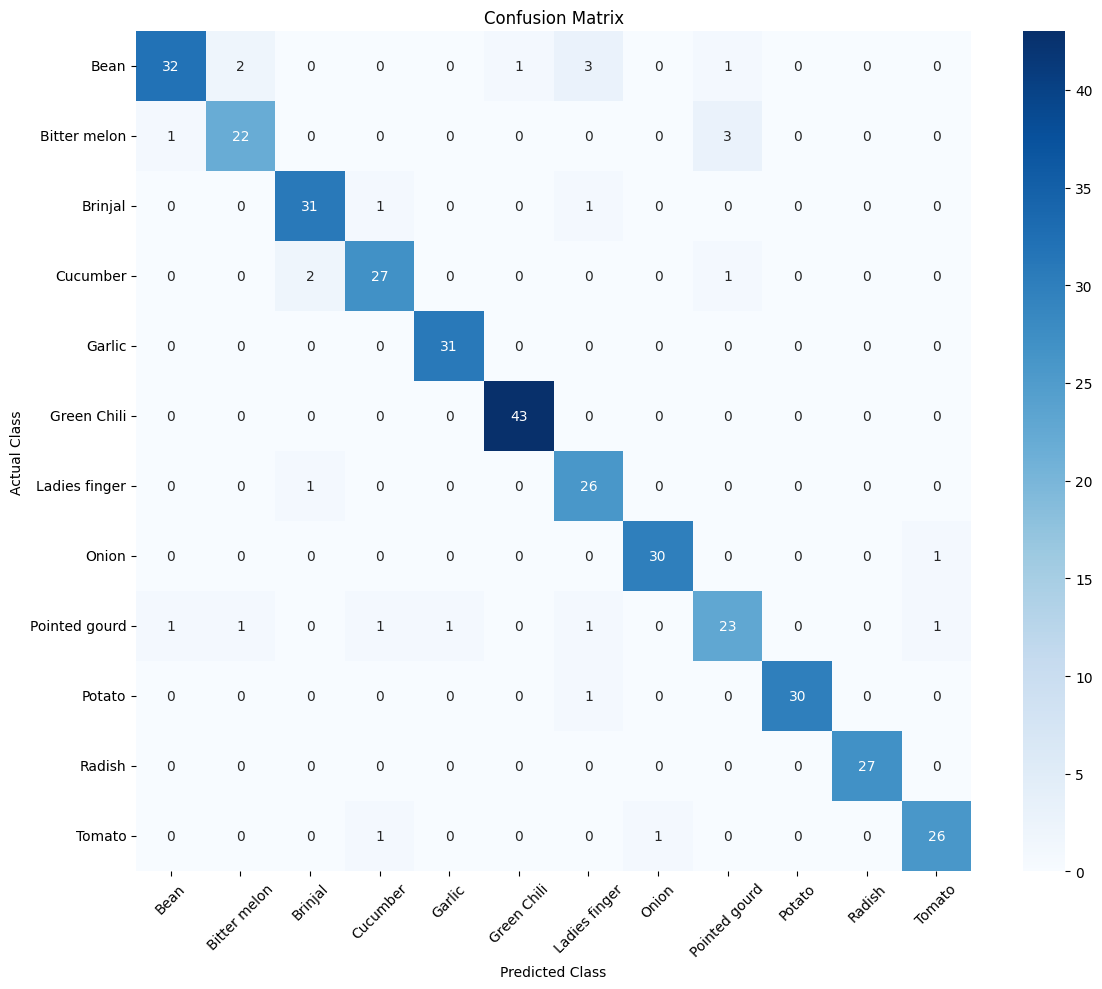

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(num_classes)
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [26]:
model.save(
    "/content/drive/MyDrive/CNN ASSIGNMENT/"
    "vegetable_cnn_model.keras"
)

print("Model saved successfully.")

Model saved successfully.
